Se faire une jolie petite carte pour visualiser le fait que la distribution spatiale inégale des infrastructures de production et des lieux principaux de consommation.
Potentiellement population is not the best and doesn't track electricity consumption by region.
Un exercice pour vérifier si avec mes points de populatoin, je retrouve plus ou moins la distribution de la consommation d'éléc

In [24]:
!pip install pandas-ods-reader


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for ezodf: filename=ezodf-0.3.2-py2.py3-none-any.whl size=49107 sha256=0e63e3cf42101a3df9d2e678097de2ee57e65e499cb3d20841abfb0ff54d009a
  Stored in directory: c:\users\dbt3kd\appdata\local\pip\cache\wheels\19\dd\9d\ccbb47390cefc7c40c72647c87ec8f681977e2dc7ebf33506a
Successfully built ezodf


In [154]:

# os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp")
# print(os.listdir())  
from pandas_ods_reader import read_ods

file_path = r"C:/Users/DBT3KD/Desktop/Etude_macro_elec/prix_electricite_gitlab\day_ahead\daily_temp\conso_elec_per_comunidad.ods"

prod_elec_com = read_ods(file_path, sheet=1)  # 0 ou 1 selon la feuille
# Equivalent to skiprows: drop first row
prod_elec_com = prod_elec_com.iloc[6:25,0:7]    # remove first row

#Remove Canarias
#Remove Aggregate line
prod_elec_com.columns = prod_elec_com.iloc[0]
# 2. Renommer la première colonne
prod_elec_com = prod_elec_com.rename(columns={prod_elec_com.columns[0]: "comunidad"})

#prod_elec_com = prod_elec_com.drop(index=[1, 5]).reset_index(drop=True)
prod_elec_com = prod_elec_com.drop(index=[6, 7, 12]).reset_index(drop=True)

# 3. Convertir uniquement les colonnes numériques pour la moyenne
cols_numeric = prod_elec_com.columns[1:]  # toutes sauf "comunidad"

# moyenne des années pour chaque communauté
prod_elec_com["conso_elec"] = prod_elec_com[cols_numeric].mean(axis=1)

# 4. Garder uniquement les colonnes finales souhaitées
prod_elec_com = prod_elec_com[["comunidad", "conso_elec"]]

prod_elec_com
#milliers d'euros de consommation
#différent de la consommation en MWh



6,comunidad,conso_elec
0,01 Andalucía,890311.5
1,02 Aragón,434183.333333
2,"03 Asturias, Principado de",481231.5
3,"04 Balears, Illes",16767.666667
4,06 Cantabria,209422.0
5,07 Castilla y León,528194.333333
6,08 Castilla - La Mancha,378213.5
7,09 Cataluña,1851398.833333
8,10 Comunitat Valenciana,894692.0
9,11 Extremadura,136774.333333


c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\geopandas\array.py:334: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  self.crs = crs
c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\geopandas\geodataframe.py:409: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  level.crs = crs


<Axes: >

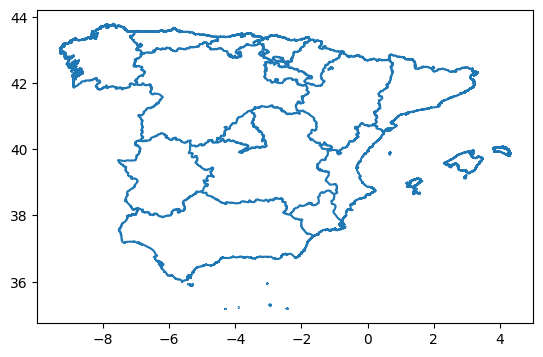

In [84]:
import geopandas as gpd

# Path to the .shp file
gdf = gpd.read_file("C:/Users/DBT3KD/Desktop/Etude_macro_elec/prix_electricite_gitlab/day_ahead/daily_temp/geo_comunidades/ll_autonomicas_inspire_peninbal_etrs89.shp")

# print(gdf.head())
# print(gdf.crs)
gdf.plot()


In [85]:
import pandas as pd

def split_line_boundaries(name_bound):
    """
    Prend un string 'Comunitat Valenciana#Mar Mediterráneo'
    ou 'Aragón#Comunitat Valenciana' et retourne une liste
    de communautés.
    """
    # Split par #
    parts = str(name_bound).split("#")
    return parts  # retourne une liste

# Créer une nouvelle colonne 'comunidades_list' contenant toutes les communautés
gdf["comunidades_list"] = gdf["NAME_BOUND"].apply(split_line_boundaries)


# Exploser la colonne pour dupliquer les lignes
gdf_exploded = gdf.explode("comunidades_list").copy()

# Renommer la colonne en 'comunidad' pour plus de clarté
gdf_exploded.rename(columns={"comunidades_list": "comunidad"}, inplace=True)
gdf_exploded[["NAME_BOUND", "comunidad"]]
# Optionnel : vérifier
#print(gdf_exploded[["NAME_BOUND", "comunidad"]].head(10))


,NAME_BOUND,comunidad
0,Comunitat Valenciana#Mar Mediterráneo,Comunitat Valenciana
0,Comunitat Valenciana#Mar Mediterráneo,Mar Mediterráneo
1,Illes Balears#Mar Mediterráneo,Illes Balears
1,Illes Balears#Mar Mediterráneo,Mar Mediterráneo
2,Galicia#Océano Atlántico,Galicia
...,...,...
4144,Galicia#Océano Atlántico,Océano Atlántico
4145,Galicia#Mar Cantábrico,Galicia
4145,Galicia#Mar Cantábrico,Mar Cantábrico
4146,Illes Balears#Mar Mediterráneo,Illes Balears


In [99]:
# Filtrer les lignes contenant "Extremadura"
extremadura_lines = gdf_exploded[gdf_exploded["NAME_BOUND"].str.contains("Extremadura", case=False, na=False)]

# Afficher
print(extremadura_lines[["NAME_BOUND", "comunidad"]])


                          NAME_BOUND           comunidad
998            Andalucía#Extremadura           Andalucía
998            Andalucía#Extremadura         Extremadura
1018     Castilla y León#Extremadura     Castilla y León
1018     Castilla y León#Extremadura         Extremadura
1031  Castilla-La Mancha#Extremadura  Castilla-La Mancha
1031  Castilla-La Mancha#Extremadura         Extremadura
1060            Extremadura#Portugal         Extremadura


In [129]:
import geopandas as gpd
from shapely.geometry import LineString, Polygon, MultiLineString
from shapely.ops import linemerge, polygonize

#exclure non-peninsular communities
#exclure non-peninsular communities
gdf_exploded = gdf_exploded[~gdf_exploded["comunidad"].isin(
	["Mar Cantábrico", "Mar Mediterráneo","Mar Mediterráneo",
  "Océano Atlántico",
  "Francia", "Territorio no asociado a ninguna autonomía", "Portugal",
  "Andorra", "Marruecos",
    "Canarias", "Ciudad Autónoma de Melilla", "Ciudad Autónoma de Ceuta",
    "Gibraltar"
  ]
)].copy()

#gdf_exploded["comunidad"].value_counts()

#["Islas Baleares", "Canarias", "Ceuta", "Melilla"]
# # Liste pour stocker les polygones
polygons = []

for comunidad, group in gdf_exploded.groupby("comunidad"):
    # Fusionner toutes les lignes de la communauté en un MultiLineString
    merged_line = linemerge(list(group.geometry))
    
    # Transformer le MultiLineString en polygones
    polys = list(polygonize(merged_line))
    
    # Si plusieurs polygones, on peut prendre le plus grand
    if len(polys) > 1:
        poly = max(polys, key=lambda p: p.area)
    else:
        poly = polys[0]
    
    polygons.append({"comunidad": comunidad, "geometry": poly})

# Créer un nouveau GeoDataFrame
gdf_exploded_poly = gpd.GeoDataFrame(polygons, crs=gdf_exploded.crs)


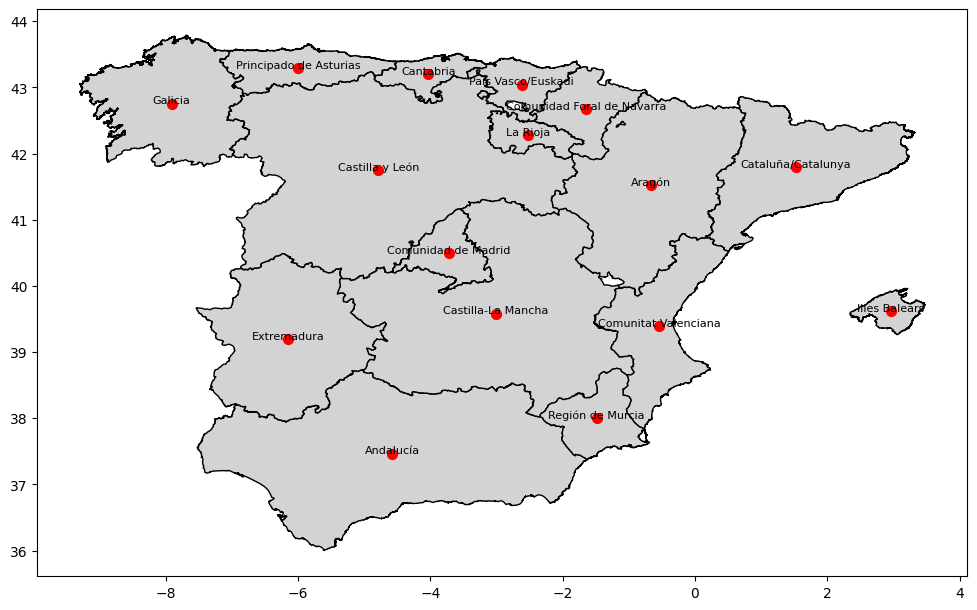

In [130]:
gdf_exploded_poly["centroid"] = gdf_exploded_poly.geometry.centroid
gdf_exploded_poly["lon"] = gdf_exploded_poly.centroid.x
gdf_exploded_poly["lat"] = gdf_exploded_poly.centroid.y
fig, ax = plt.subplots(figsize=(12,12))
gdf_exploded_poly.plot(ax=ax, color="lightgrey", edgecolor="black")
gdf_exploded_poly.centroid.plot(ax=ax, color="red", markersize=50)

for x, y, label in zip(gdf_exploded_poly["lon"], gdf_exploded_poly["lat"], gdf_exploded_poly["comunidad"]):
    ax.text(x, y, label, fontsize=8, ha="center")

plt.show()

In [156]:
print(gdf_exploded_poly["comunidad"].unique())
print(prod_elec_com["comunidad"].unique())

['Andalucía' 'Aragón' 'Cantabria' 'Castilla y León' 'Castilla-La Mancha'
 'Cataluña/Catalunya' 'Comunidad Foral de Navarra' 'Comunidad de Madrid'
 'Comunitat Valenciana' 'Extremadura' 'Galicia' 'Illes Balears' 'La Rioja'
 'País Vasco/Euskadi' 'Principado de Asturias' 'Región de Murcia']
['01 Andalucía' '02 Aragón' '03 Asturias, Principado de'
 '04 Balears, Illes' '06 Cantabria' '07 Castilla y León'
 '08 Castilla - La Mancha' '09 Cataluña' '10 Comunitat Valenciana'
 '11 Extremadura' '12 Galicia' '13 Madrid, Comunidad de'
 '14 Murcia, Región de' '15 Navarra, Comunidad Foral de' '16 País Vasco'
 '17 Rioja, La']


In [157]:
# Dictionnaire de mapping : shapefile_name -> consumption_name
mapping = {
    'Andalucía': '01 Andalucía',
    'Aragón': '02 Aragón',
    'Principado de Asturias': '03 Asturias, Principado de',
    'Illes Balears': '04 Balears, Illes',
    'Cantabria': '06 Cantabria',
    'Castilla y León': '07 Castilla y León',
    'Castilla-La Mancha': '08 Castilla - La Mancha',
    'Cataluña/Catalunya': '09 Cataluña',
    'Comunitat Valenciana': '10 Comunitat Valenciana',
    'Extremadura': '11 Extremadura',
    'Galicia': '12 Galicia',
    'Comunidad de Madrid': '13 Madrid, Comunidad de',
    'Región de Murcia': '14 Murcia, Región de',
    'Comunidad Foral de Navarra': '15 Navarra, Comunidad Foral de',
    'País Vasco/Euskadi': '16 País Vasco',
	'La Rioja': '17 Rioja, La'
}
# mapping inversé : consommation_name -> shapefile_name
mapping_inv = {v: k for k, v in mapping.items()}

prod_elec_com["comunidad_shapefile"] = prod_elec_com["comunidad"].map(mapping_inv)


# Fusionner le GeoDataFrame avec le dataframe de consommation
gdf_merged = gdf_exploded_poly.merge(
    prod_elec_com[["comunidad_shapefile", "conso_elec"]],
    left_on="comunidad",
    right_on="comunidad_shapefile",
    how="left"
)

# Vérifier
print(gdf_merged[["comunidad", "conso_elec"]].head())



            comunidad     conso_elec
0           Andalucía       890311.5
1              Aragón  434183.333333
2           Cantabria       209422.0
3     Castilla y León  528194.333333
4  Castilla-La Mancha       378213.5


Utiliser sample dots
pour prédire la part de conso élec par région
pour voir quelle erreur on fait dans la distrib spatiale de la conso.
Peut-on calibrer les points sur leur représentativité par part dans la conso de la région ?

In [158]:
import os
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
pop_dots = pd.read_csv("sample_pop_dots.csv")

import geopandas as gpd
from shapely.geometry import Point

# Supposons que ton DataFrame de points s'appelle pop_dots
geometry = [Point(xy) for xy in zip(pop_dots["longitude"], pop_dots["latitude"])]
gpop_dots = gpd.GeoDataFrame(pop_dots, geometry=geometry, crs="EPSG:4326")  # WGS84
# Chaque point prendra les attributs du polygone dans lequel il se trouve
gdf_points_with_region = gpd.sjoin(gpop_dots, gdf_merged, how="left", predicate='within')

# Vérifier
print(gdf_points_with_region[["longitude", "latitude", "comunidad"]])


    longitude   latitude             comunidad
0   -1.654167  40.548333                Aragón
1   -0.386667  39.421667  Comunitat Valenciana
2   -4.059167  43.355000             Cantabria
3   -4.260833  40.918333       Castilla y León
4   -6.180833  37.965000           Extremadura
..        ...        ...                   ...
95  -0.368333  42.516667                Aragón
96  -0.747500  38.874167  Comunitat Valenciana
97  -1.800833  37.231667             Andalucía
98  -5.819167  37.610833             Andalucía
99   0.990833  41.742500    Cataluña/Catalunya

[100 rows x 3 columns]


c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\geopandas\array.py:334: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  self.crs = crs
c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\geopandas\geodataframe.py:409: UserWarning: Cannot set the CRS, falling back to None. The CRS support requires the 'pyproj' package, but it is not installed or does not import correctly. The functions depending on CRS will raise an error or may produce unexpected results.
  level.crs = crs


In [ ]:

# Compter le nombre de points par comunidad
points_count = gdf_points_with_region.groupby("comunidad").size().reset_index(name="n_points")

gdf_exploded_map = gdf_merged.merge(
    points_count,
    on="comunidad",
    how="left"
)
gdf_exploded_map["n_points"] = gdf_exploded_map["n_points"].fillna(0)
# Somme totale des points et de la consommation
total_points = gdf_exploded_map["n_points"].sum()
total_conso = gdf_exploded_map["conso_elec"].sum()
# Pourcentage de points
gdf_exploded_map["points_pct"] = 100 * gdf_exploded_map["n_points"] / total_points

# Pourcentage de consommation électrique
gdf_exploded_map["conso_pct"] = 100 * gdf_exploded_map["conso_elec"] / total_conso
# Calcul de la différence
gdf_exploded_map["diff_pct"] = gdf_exploded_map["conso_pct"] - gdf_exploded_map["points_pct"]



In [163]:
gdf_exploded_map[["comunidad", "points_pct",  "conso_pct", "diff_pct"]]

,comunidad,points_pct,conso_pct,diff_pct
0,Andalucía,22.448980,10.631898,-11.817082
1,Aragón,3.061224,5.184919,2.123694
2,Cantabria,2.040816,2.50087,0.460054
3,Castilla y León,3.061224,6.307577,3.246352
4,Castilla-La Mancha,4.081633,4.51654,0.434907
5,Cataluña/Catalunya,13.265306,22.108984,8.843678
6,Comunidad Foral de Navarra,3.061224,3.610581,0.549357
7,Comunidad de Madrid,19.387755,4.639518,-14.748237
8,Comunitat Valenciana,9.183673,10.684208,1.500535
9,Extremadura,5.102041,1.633328,-3.468713


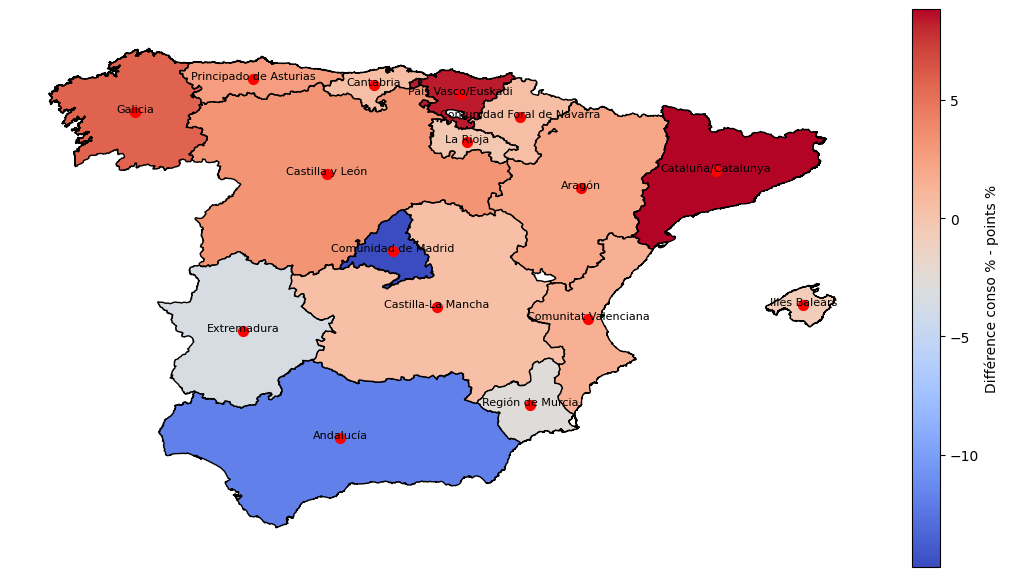

In [162]:
import matplotlib.pyplot as plt
import matplotlib as mpl


fig, ax = plt.subplots(figsize=(12,12))

# Créer une colormap continue
cmap = plt.cm.coolwarm
vmin = gdf_exploded_map["diff_pct"].min()
vmax = gdf_exploded_map["diff_pct"].max()

# Plot des polygones avec couleur selon diff_pct
gdf_exploded_map.plot(
    ax=ax,
    color=gdf_exploded_map["diff_pct"].apply(lambda x: cmap((x - vmin)/(vmax - vmin))),
    edgecolor="black"
)

# Centroids
gdf_exploded_map.centroid.plot(ax=ax, color="red", markersize=50)

# Ajouter les noms
for geom, label in zip(gdf_exploded_map.centroid, gdf_exploded_map["comunidad"]):
    ax.text(geom.x, geom.y, label, fontsize=8, ha="center")

# Créer une colorbar continue
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm._A = []  # nécessaire pour ScalarMappable
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label("Différence conso % - points %")

ax.set_axis_off()
plt.show()


Résultats: il serait abusif de prendre simplement la densité de population pour la consommation d'éléctricité,
on remarque que Madrid est surreprésenté,
au contraire les régions industrielles comme le pays basque et la Catalogne sont sous-représentées
on propose de calibrer le poids des points de densité sur la conso annuelle par province.
L'hypothèse implicite étant que au sein de la province, la consommation est répartie spatialement selon la densité de population


In [167]:
# Calcul du facteur par comunidad
gdf_exploded_map["factor"] = gdf_exploded_map["conso_pct"] / gdf_exploded_map["points_pct"]

# Appliquer ce facteur aux n_points pour obtenir n_points_corrigé
gdf_exploded_map["n_points_corrige"] = gdf_exploded_map["n_points"] * gdf_exploded_map["factor"]

type(gdf_exploded_map["n_points_corrige"].iloc[0])
# Vérification
total_points_corrige = gdf_exploded_map["n_points_corrige"].sum()

summary = gdf_exploded_map.groupby("comunidad").agg(
    points_corrige_pct=("n_points_corrige", lambda x: x.sum() / total_points_corrige * 100),
    conso_pct=("conso_pct", "first")
)
print(summary)



                            points_corrige_pct  conso_pct
comunidad                                                
Andalucía                            10.631898  10.631898
Aragón                                5.184919   5.184919
Cantabria                             2.500870    2.50087
Castilla y León                       6.307577   6.307577
Castilla-La Mancha                    4.516540    4.51654
Cataluña/Catalunya                   22.108984  22.108984
Comunidad Foral de Navarra            3.610581   3.610581
Comunidad de Madrid                   4.639518   4.639518
Comunitat Valenciana                 10.684208  10.684208
Extremadura                           1.633328   1.633328
Galicia                               7.758128   7.758128
Illes Balears                         0.200236   0.200236
La Rioja                              0.739966   0.739966
País Vasco/Euskadi                   10.350832  10.350832
Principado de Asturias                5.746757   5.746757
Región de Murc

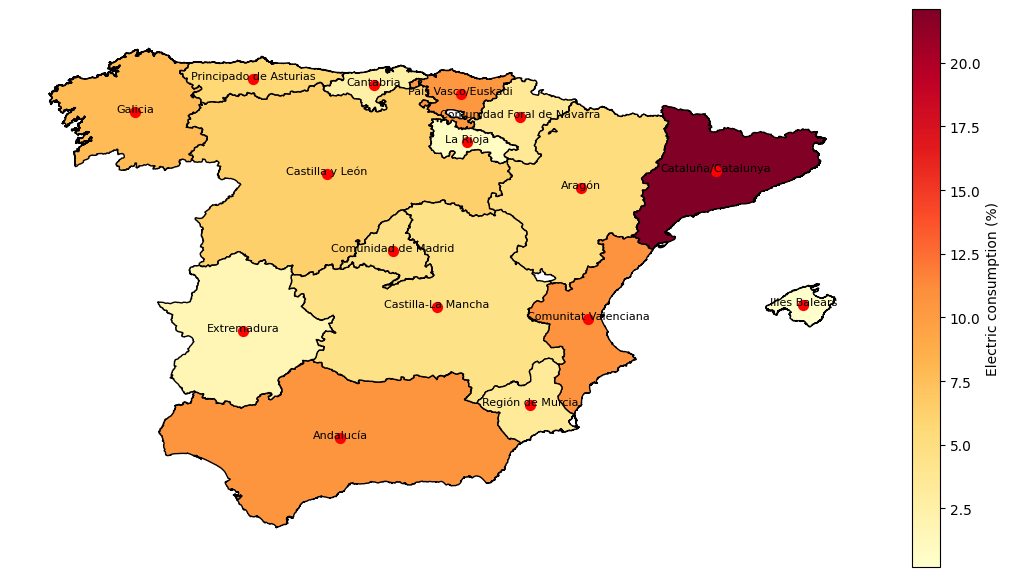

In [171]:
import matplotlib.pyplot as plt
import matplotlib as mpl


fig, ax = plt.subplots(figsize=(12,12))

# Créer une colormap continue
# Créer une colormap continue jaune → rouge
cmap = plt.cm.YlOrRd
vmin = gdf_exploded_map["conso_pct"].min()
vmax = gdf_exploded_map["conso_pct"].max()


# Plot des polygones avec couleur selon conso_pct
gdf_exploded_map.plot(
    ax=ax,
    color=gdf_exploded_map["conso_pct"].apply(lambda x: cmap((x - vmin)/(vmax - vmin))),
    edgecolor="black"
)

# Centroids
gdf_exploded_map.centroid.plot(ax=ax, color="red", markersize=50)

# Ajouter les noms
for geom, label in zip(gdf_exploded_map.centroid, gdf_exploded_map["comunidad"]):
    ax.text(geom.x, geom.y, label, fontsize=8, ha="center")

# Créer une colorbar continue
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm._A = []  # nécessaire pour ScalarMappable
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label("Electric consumption (%)")

ax.set_axis_off()
plt.show()


In [180]:
# Calcul du facteur par comunidad
#gdf_exploded_map["factor"] = gdf_exploded_map["conso_pct"] / gdf_exploded_map["points_pct"]
# gpop_dots = gpd.GeoDataFrame(pop_dots, geometry=geometry, crs="EPSG:4326")  # WGS84
# # Chaque point prendra les attributs du polygone dans lequel il se trouve
# gdf_points_with_region = gpd.sjoin(gpop_dots, gdf_merged, how="left", predicate='within')


gdf_demand_points = pd.merge(
	gdf_points_with_region,
	gdf_exploded_map[["comunidad", "factor"]],
	on="comunidad",
	how="left"
)
os.getcwd()
gdf_demand_points.to_csv("demand_points_corrected.csv", index=False)

gdf_demand_points.head()

,longitude,latitude,geometry,index_right,comunidad,centroid,lon,lat,comunidad_shapefile,conso_elec,factor
0,-1.654167,40.548333,POINT (-1.65417 40.54833),1.0,Aragón,POINT (-0.66031 41.5191),-0.660307,41.519101,Aragón,434183.333333,1.69374
1,-0.386667,39.421667,POINT (-0.38667 39.42167),8.0,Comunitat Valenciana,POINT (-0.54305 39.39043),-0.543049,39.390433,Comunitat Valenciana,894692.0,1.163392
2,-4.059167,43.355000,POINT (-4.05917 43.355),2.0,Cantabria,POINT (-4.0321 43.19756),-4.032097,43.197562,Cantabria,209422.0,1.225426
3,-4.260833,40.918333,POINT (-4.26083 40.91833),3.0,Castilla y León,POINT (-4.78826 41.75132),-4.788259,41.751320,Castilla y León,528194.333333,2.060475
4,-6.180833,37.965000,POINT (-6.18083 37.965),9.0,Extremadura,POINT (-6.15066 39.19143),-6.150658,39.191427,Extremadura,136774.333333,0.320132


In [181]:
print(os.getcwd())

C:\Users\DBT3KD\Desktop\Etude_macro_elec\prix_electricite_gitlab\day_ahead\daily_temp\outputs
